In [ ]:
from dotenv import load_dotenv
import os

load_dotenv()

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")


In [ ]:
from langchain.chat_models import init_chat_model

def get_model():
    return init_chat_model(model="google_genai:gemini-3.7-flash")

model = get_model()


In [16]:
from typing_extensions import Annotated, TypedDict
from langgraph.graph.message import add_messages


class State(TypedDict):
    messages:Annotated[list,add_messages]

def chatbot(state:State)->State:
    return {"messages":[model.invoke(state["messages"])]}



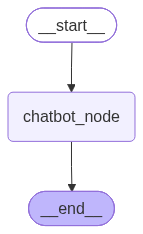

In [17]:
from langgraph.graph import START,StateGraph,END


builder = StateGraph(State)

builder.add_node("chatbot_node",chatbot)

builder.add_edge(START,"chatbot_node")
builder.add_edge("chatbot_node",END)

graph = builder.compile()
graph

In [18]:
message = {
    "role":"user",
    "content":"Hello, who are you? Can you help me"
}
response = graph.invoke({"messages":[message]})
result = response["messages"]

In [19]:
result

[HumanMessage(content='Hello, who are you? Can you help me', additional_kwargs={}, response_metadata={}, id='8f589cd5-a349-4f05-bdf4-5a88ae9e9145'),
 AIMessage(content=[{'type': 'text', 'text': 'Hello! I am Gemini, a large language model built by Google. \n\nI would be happy to help you. What are you working on or what questions do you have today?', 'extras': {'signature': 'EoAHCv0GARFNMg+8FW0yvgLMBoXy2/0h+NB7GcPg7GeI4Bh6kAG2fLrVqTzGol72ie/sKfo97yiAJSo1RmVpu/BDHictnmtCz8Bn5m0R0U7Zrsc+ShW4KiX20CrIHBTc3mq2f/re12DBm/PylUumf5B0JHQ7/qd1Nwdqau5MbHO1EO81LhMOV5Enm6PJ51GLc0o5oEKeEUbbbJCA7zmdw57bTvuDJc0TLbjJPz0AX31r3Dzvly+YiL4Nid4ndi1lQ32EH6L+mUULXauVbhNqNB5GJKbZ/DKaYQNiICkEonS350sapmC99u6tnuYKB1R58qugYNN5ij87QHnoqDsSlQvahCwXkMTCTcuCSuHDwBkTa+GGkOaa4YzcupNaYpbGvN1S5ze96Gd9DxOfQeV2Wzez/rvxI7TDPYGdW2/NsfvbMRI4DP+5MiTU6DkT2p2KI1gq4SvWA1SZOWKhYzPQvTH+FyQ1zsN9D00d6tlUhlIyi5edM8WWiLLQhtSH00AQUIxR450sk275gujxI8sQo7AFAyY17glOkUMynsqV1mU7fXUi9iIc3OqYPkvl102nZbrtNWWnXH4K7g7MYhAl/lhCYqkd1mGhXjstQVe/Qa4IOzD